# Training and evaluation of seven CNNs: internal and external test

This notebook contains the complete analysis pipeline of the study.

1. Loads the cleaned development data (`oral_clean/split.csv`) and the external cohort list (`external_piyarathne/external.csv`).
2. Trains seven ImageNet-pretrained CNNs with three seeds each (0, 1, 2). Augmentation is applied only to training images, during training.
3. Uses the validation set only to select the checkpoint and the locked seed of each model.
4. Evaluates the locked models on the internal test set (95% CIs, DeLong and exact McNemar tests).
5. Applies the locked models to the external cohort without re-tuning (image and patient level).
6. Generates all figures from the stored outputs.

**Order of the analysis.** Steps 1–14 were first run on the partition produced by the perceptual-hash audit, including evaluation on both test sets. The deep-feature audit (Step 15) was then added, and the four images it identified were removed (review and removal cells after Step 16). Steps 1–14 were subsequently re-run from the beginning with an unchanged protocol, selection rule and threshold. The outputs saved in this notebook are those of the repeated analysis (lock file written 2026-09-23 10:21:55), and all reported results come from this run. Step 17 (local threshold recalibration) is a secondary analysis added after the primary external results were available.

**Environment:** Google Colab, NVIDIA T4 GPU. Completed runs are stored on Drive and skipped when the notebook is re-run. `QUICK_TEST = True` runs a reduced pipeline check (1 seed, 3 models, 2 + 2 epochs).

## Step 1: Connect Drive and check the GPU

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
PROJECT   = Path('/content/drive/MyDrive/oral project')     # project folder on Google Drive
CLEAN_DIR = Path('/content/drive/MyDrive/oral project/oral_clean')
EXT_DIR   = Path('/content/drive/MyDrive/oral project/external_piyarathne')
for p in (CLEAN_DIR / 'split.csv', EXT_DIR / 'external.csv'):
    print(p, 'OK' if p.exists() else 'NOT FOUND - check PROJECT folder name')
!nvidia-smi --query-gpu=name,memory.total --format=csv

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/oral project/oral_clean/split.csv OK
/content/drive/MyDrive/oral project/external_piyarathne/external.csv OK
name, memory.total [MiB]
Tesla T4, 15360 MiB


## Step 2: Settings

All hyperparameters are defined in this cell and were fixed before training (manuscript Table 4).

In [ ]:
QUICK_TEST = False          # True = 1 seed, 2+2 epochs, 3 models: only to check the pipeline

MODELS = ["ResNet50", "VGG16", "MobileNetV2", "DenseNet121", "EfficientNetB0", "Xception", "InceptionV3"]
PRIMARY_MODEL = "ResNet50"  # prespecified primary model (the aim of the study)
SEEDS = [0, 1, 2]

IMG_SIZE = 224
BATCH_SIZE = 16
HEAD_EPOCHS, HEAD_LR = 10, 1e-3        # stage 1: backbone frozen, train new head
FT_EPOCHS,   FT_LR   = 40, 1e-5        # stage 2: fine-tune top layers
FT_FRACTION = 0.30                     # fraction of backbone layers unfrozen in stage 2 (BatchNorm stays frozen)
DENSE_UNITS, DROPOUT = 256, 0.30
ES_PATIENCE, LR_PATIENCE, LR_FACTOR, MIN_LR = 5, 2, 0.5, 1e-7
USE_CLASS_WEIGHTS = True               # 'balanced' class weights in the loss
THRESHOLD = 0.5                        # prespecified decision threshold
AUG = dict(flip="horizontal", rotation_deg=15, translation=0.10, zoom=0.10, brightness=0.10)
N_BOOT = 2000                          # bootstrap resamples for CIs
WEIGHTS = "imagenet"

if QUICK_TEST:
    MODELS, SEEDS = ["ResNet50", "DenseNet121", "EfficientNetB0"], [0]
    HEAD_EPOCHS, FT_EPOCHS = 2, 2

RESULTS = PROJECT / ("results_quicktest" if QUICK_TEST else "results_v2")
RUNS, TABLES, FIGS = RESULTS / "runs", RESULTS / "tables", RESULTS / "figures"
for p in (RUNS, TABLES, FIGS):
    p.mkdir(parents=True, exist_ok=True)
print("Results folder:", RESULTS)

Results folder: /content/drive/MyDrive/oral project/results_v2


## Step 3: Imports

In [ ]:
import os, json, time, random, platform, warnings
import numpy as np, pandas as pd
import tensorflow as tf, keras
from keras import layers, ops
from PIL import Image, ImageOps
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, brier_score_loss
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore", category=UserWarning); warnings.filterwarnings("ignore", category=RuntimeWarning)
tf.get_logger().setLevel("ERROR")
pd.set_option("display.width", 220, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "font.family": "DejaVu Sans"})
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.20.0 | Keras 3.13.2 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 4: Load all images into memory (resized to 224×224)
Images are read once from Drive. No augmentation happens here.

In [ ]:
def load_image(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        im = im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        return np.asarray(im, dtype=np.uint8)

split = pd.read_csv(CLEAN_DIR / "split.csv")
split["y"] = (split.label == "cancer").astype(int)
split["path"] = [str(CLEAN_DIR / p) for p in split.clean_path]
ext = pd.read_csv(EXT_DIR / "external.csv")
ext["y"] = (ext.label == "cancer").astype(int)
ext["path"] = [str(EXT_DIR / p) for p in ext.ext_path]

DATA = {}
for name in ("train", "val", "test"):
    d = split[split.split == name].reset_index(drop=True)
    DATA[name] = dict(df=d, X=np.stack([load_image(p) for p in d.path]), y=d.y.values)
DATA["external"] = dict(df=ext, X=np.stack([load_image(p) for p in ext.path]), y=ext.y.values)

summary = pd.DataFrame({k: {"images": len(v["y"]), "cancer": int(v["y"].sum()), "normal": int((1 - v["y"]).sum())}
                        for k, v in DATA.items()}).T
display(summary)

,images,cancer,normal
train,733,399,334
val,156,85,71
test,156,85,71
external,813,126,687


## Step 5: Model definition

Every model gets the same pipeline: **augmentation (training only) → the model's own ImageNet preprocessing → pretrained backbone → global average pooling → dropout → dense(256, ReLU) → dropout → sigmoid**.
Keras random-augmentation layers are automatically switched off at validation/test time.

In [ ]:
APPS = {"ResNet50": keras.applications.ResNet50, "VGG16": keras.applications.VGG16,
        "MobileNetV2": keras.applications.MobileNetV2, "DenseNet121": keras.applications.DenseNet121,
        "EfficientNetB0": keras.applications.EfficientNetB0, "Xception": keras.applications.Xception,
        "InceptionV3": keras.applications.InceptionV3}
PREP_MODE = {"ResNet50": "caffe", "VGG16": "caffe", "MobileNetV2": "tf", "DenseNet121": "torch",
             "EfficientNetB0": "none", "Xception": "tf", "InceptionV3": "tf"}   # Keras preprocess_input equivalents

def preprocess(x, mode):
    if mode == "caffe":                                   # RGB->BGR, subtract ImageNet mean
        return ops.flip(x, axis=-1) - ops.convert_to_tensor([103.939, 116.779, 123.68])
    if mode == "tf":                                      # scale to [-1, 1]
        return x / 127.5 - 1.0
    if mode == "torch":                                   # [0,1] then ImageNet mean/std
        return (x / 255.0 - ops.convert_to_tensor([0.485, 0.456, 0.406])) / ops.convert_to_tensor([0.229, 0.224, 0.225])
    return x                                              # EfficientNet rescales internally

def augmenter(seed):
    return keras.Sequential([
        layers.RandomFlip(AUG["flip"], seed=seed),
        layers.RandomRotation(AUG["rotation_deg"] / 360.0, fill_mode="reflect", seed=seed),
        layers.RandomTranslation(AUG["translation"], AUG["translation"], fill_mode="reflect", seed=seed),
        layers.RandomZoom(AUG["zoom"], fill_mode="reflect", seed=seed),
        layers.RandomBrightness(AUG["brightness"], value_range=(0, 255), seed=seed),
    ], name="augmentation")

NON_BACKBONE = {"augmentation", "preprocess"}

def build_model(name, seed, weights=WEIGHTS):
    keras.utils.set_random_seed(seed)
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")          # raw pixels 0-255
    x = augmenter(seed)(inp)
    x = layers.Lambda(lambda t: preprocess(t, PREP_MODE[name]), name="preprocess")(x)
    base = APPS[name](include_top=False, weights=weights, input_tensor=x)
    feat = base.output                                                  # last conv feature map (for Grad-CAM)
    h = layers.GlobalAveragePooling2D(name="gap")(feat)
    h = layers.Dropout(DROPOUT, name="drop1")(h)
    h = layers.Dense(DENSE_UNITS, activation="relu", name="dense")(h)
    h = layers.Dropout(DROPOUT, name="drop2")(h)
    out = layers.Dense(1, activation="sigmoid", name="prob")(h)
    model = keras.Model(inp, out, name=name)
    backbone = [l for l in base.layers if l.name not in NON_BACKBONE and not isinstance(l, keras.layers.InputLayer)]
    return model, backbone, feat

m, bb, _ = build_model("ResNet50", 0, weights=None)
print("ResNet50 backbone layers:", len(bb), "| total params:", f"{m.count_params():,}")
del m, bb; keras.backend.clear_session()

ResNet50 backbone layers: 174 | total params: 24,112,513


## Step 6: Train all models (7 models × 3 seeds)

Two stages per run: (1) backbone frozen, train head; (2) unfreeze top 30% of backbone layers and fine-tune with a small learning rate.
Early stopping and learning-rate reduction watch **validation loss** only. The best validation checkpoint is restored.
Each finished run is saved to Drive (`results/runs/…`) and skipped when the notebook is re-run.

In [ ]:
def make_ds(X, y, training, seed):
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype("float32")))
    if training:
        ds = ds.shuffle(len(y), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def class_weights(y):
    if not USE_CLASS_WEIGHTS:
        return None
    n, pos = len(y), y.sum()
    return {0: n / (2 * (n - pos)), 1: n / (2 * pos)}

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=ES_PATIENCE, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=LR_FACTOR, patience=LR_PATIENCE, min_lr=MIN_LR)]

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])

def predict(model, X):
    return model.predict(X.astype("float32"), batch_size=32, verbose=0).ravel()

def train_one(name, seed):
    rdir = RUNS / f"{name}_seed{seed}"
    if (rdir / "done.json").exists():
        print(f"[skip] {name} seed {seed} (already done)"); return
    rdir.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    model, backbone, _ = build_model(name, seed)
    tr = make_ds(DATA["train"]["X"], DATA["train"]["y"], True, seed)
    va = make_ds(DATA["val"]["X"], DATA["val"]["y"], False, seed)
    cw = class_weights(DATA["train"]["y"])

    for l in backbone: l.trainable = False
    compile_model(model, HEAD_LR)
    h1 = model.fit(tr, validation_data=va, epochs=HEAD_EPOCHS, class_weight=cw, callbacks=callbacks(), verbose=0)

    n_ft = int(round(len(backbone) * FT_FRACTION))
    for l in backbone[-n_ft:]:
        l.trainable = not isinstance(l, layers.BatchNormalization)
    compile_model(model, FT_LR)
    e1 = len(h1.epoch)
    h2 = model.fit(tr, validation_data=va, epochs=e1 + FT_EPOCHS, initial_epoch=e1, class_weight=cw,
                   callbacks=callbacks(), verbose=0)

    hist = pd.concat([pd.DataFrame(h1.history).assign(stage=1, epoch=np.arange(1, e1 + 1)),
                      pd.DataFrame(h2.history).assign(stage=2, epoch=np.arange(e1 + 1, e1 + len(h2.epoch) + 1))])
    hist.to_csv(rdir / "history.csv", index=False)
    model.save_weights(rdir / "best.weights.h5")

    rows = []
    for part in ("val", "test"):                        # external is NOT predicted here
        d = DATA[part]
        rows.append(pd.DataFrame({"split": part, "file": d["df"].clean_path, "y": d["y"], "prob": predict(model, d["X"])}))
    pd.concat(rows).to_csv(rdir / "preds.csv", index=False)

    info = dict(model=name, seed=seed, stage1_epochs=e1, stage2_epochs=len(h2.epoch),
                best_val_loss_stage2=float(np.min(h2.history["val_loss"])),
                trainable_params_stage2=int(sum(np.prod(w.shape) for w in model.trainable_weights)),
                total_params=int(model.count_params()), unfrozen_backbone_layers=n_ft,
                backbone_layers=len(backbone), minutes=round((time.time() - t0) / 60, 1))
    json.dump(info, open(rdir / "done.json", "w"), indent=2)
    print(f"[done] {name} seed {seed}: epochs {e1}+{len(h2.epoch)}, {info['minutes']} min")
    del model; keras.backend.clear_session()

for name in MODELS:
    for seed in SEEDS:
        train_one(name, seed)
print("All training runs finished.")

[done] ResNet50 seed 0: epochs 10+9, 2.3 min
[done] ResNet50 seed 1: epochs 7+9, 2.0 min
[done] ResNet50 seed 2: epochs 10+8, 2.1 min
[done] VGG16 seed 0: epochs 10+15, 2.3 min
[done] VGG16 seed 1: epochs 10+23, 2.7 min
[done] VGG16 seed 2: epochs 10+18, 2.3 min
[done] MobileNetV2 seed 0: epochs 10+14, 1.3 min
[done] MobileNetV2 seed 1: epochs 10+7, 1.0 min
[done] MobileNetV2 seed 2: epochs 10+6, 1.0 min
[done] DenseNet121 seed 0: epochs 10+13, 3.3 min
[done] DenseNet121 seed 1: epochs 10+9, 2.6 min
[done] DenseNet121 seed 2: epochs 10+18, 3.5 min
[done] EfficientNetB0 seed 0: epochs 10+12, 1.8 min
[done] EfficientNetB0 seed 1: epochs 10+6, 1.5 min
[done] EfficientNetB0 seed 2: epochs 9+7, 1.5 min
[done] Xception seed 0: epochs 10+10, 2.5 min
[done] Xception seed 1: epochs 10+9, 2.4 min
[done] Xception seed 2: epochs 10+9, 2.3 min
[done] InceptionV3 seed 0: epochs 10+9, 2.0 min
[done] InceptionV3 seed 1: epochs 10+9, 1.8 min
[done] InceptionV3 seed 2: epochs 10+9, 1.8 min
All training 

## Step 7: Statistics functions
Wilson CIs for proportions, DeLong for AUC, bootstrap for the rest, exact McNemar, Holm correction.

In [ ]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (max(0.0, c - h), min(1.0, c + h))

def confusion(y, p, thr=THRESHOLD):
    yh = (p >= thr).astype(int)
    return (int(((y == 0) & (yh == 0)).sum()), int(((y == 0) & (yh == 1)).sum()),
            int(((y == 1) & (yh == 0)).sum()), int(((y == 1) & (yh == 1)).sum()))

def point_metrics(y, p, thr=THRESHOLD):
    tn, fp, fn, tp = confusion(y, p, thr); n = tn + fp + fn + tp
    sens = tp / (tp + fn) if tp + fn else np.nan; spec = tn / (tn + fp) if tn + fp else np.nan
    ppv = tp / (tp + fp) if tp + fp else np.nan;  npv = tn / (tn + fn) if tn + fn else np.nan
    po = (tp + tn) / n; pe = ((tp + fp) * (tp + fn) + (tn + fn) * (tn + fp)) / n**2
    two = len(np.unique(y)) == 2
    return dict(accuracy=po, balanced_accuracy=(sens + spec) / 2, sensitivity=sens, specificity=spec,
                ppv=ppv, npv=npv, f1=2 * tp / (2 * tp + fp + fn) if tp else 0.0,
                kappa=(po - pe) / (1 - pe) if pe < 1 else np.nan,
                auc=roc_auc_score(y, p) if two else np.nan, pr_auc=average_precision_score(y, p) if two else np.nan,
                brier=brier_score_loss(y, p), tn=tn, fp=fp, fn=fn, tp=tp)

# ---- DeLong (fast implementation, Sun & Xu 2014) ----
def _midrank(x):
    J = np.argsort(x, kind="mergesort"); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]: j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1; i = j
    out = np.empty(N); out[J] = T; return out

def delong_cov(y, preds):
    preds = np.atleast_2d(preds); y = np.asarray(y)
    order = np.argsort(-y, kind="mergesort"); P = preds[:, order]; m = int(y.sum()); n = len(y) - m
    tx = np.array([_midrank(r[:m]) for r in P]); ty = np.array([_midrank(r[m:]) for r in P])
    tz = np.array([_midrank(r) for r in P])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n; v10 = 1.0 - (tz[:, m:] - ty) / m
    cov = np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
    return aucs, cov

def delong_ci(y, p):
    auc, cov = delong_cov(y, p); se = np.sqrt(cov[0, 0])
    return (max(0, auc[0] - 1.96 * se), min(1, auc[0] + 1.96 * se))

def delong_test(y, p1, p2):
    aucs, cov = delong_cov(y, np.vstack([p1, p2]))
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    z = (aucs[0] - aucs[1]) / np.sqrt(var) if var > 0 else 0.0
    return aucs[0] - aucs[1], 2 * stats.norm.sf(abs(z))

def mcnemar_exact(y, p1, p2, thr=THRESHOLD):
    c1 = (p1 >= thr).astype(int) == y; c2 = (p2 >= thr).astype(int) == y
    b, c = int((c1 & ~c2).sum()), int((~c1 & c2).sum())
    return b, c, (stats.binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0)

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for r, i in enumerate(order):
        run = max(run, min(1, (m - r) * p[i])); adj[i] = run
    return adj

def bootstrap_ci(y, p, keys, groups=None, n_boot=N_BOOT, seed=42):
    """Percentile CIs. If groups (patient IDs) are given, patients are resampled (cluster bootstrap)."""
    rng = np.random.default_rng(seed)
    if groups is None:
        units = [np.array([i]) for i in range(len(y))]
    else:
        g = pd.Series(np.arange(len(y))).groupby(np.asarray(groups)).apply(np.array)
        units = list(g.values)
    vals = {k: [] for k in keys}
    for _ in range(n_boot):
        idx = np.concatenate([units[i] for i in rng.integers(0, len(units), len(units))])
        if len(np.unique(y[idx])) < 2: continue
        m = point_metrics(y[idx], p[idx])
        for k in keys: vals[k].append(m[k])
    return {k: (np.nanpercentile(v, 2.5), np.nanpercentile(v, 97.5)) for k, v in vals.items()}

def fmt(v, ci=None, d=3):
    return f"{v:.{d}f}" if ci is None else f"{v:.{d}f} ({ci[0]:.{d}f}–{ci[1]:.{d}f})"

# sanity check of DeLong against sklearn
_y = np.r_[np.zeros(50), np.ones(40)].astype(int); _p = np.random.default_rng(1).random(90) + _y * 0.3
assert abs(delong_cov(_y, _p)[0][0] - roc_auc_score(_y, _p)) < 1e-9
print("Statistics functions ready (DeLong check passed).")

Statistics functions ready (DeLong check passed).


## Step 8: Model selection on the validation set, then lock

For each model, the **locked seed** is the seed with the highest validation AUC.
The best comparator on validation is also reported. **Nothing from the test sets is used here.** A `lock.json` file records the decision before any test result of this run is computed.

In [ ]:
def load_run(name, seed):
    r = RUNS / f"{name}_seed{seed}"
    return pd.read_csv(r / "preds.csv"), pd.read_csv(r / "history.csv"), json.load(open(r / "done.json"))

val_rows = []
for name in MODELS:
    for seed in SEEDS:
        pr, _, info = load_run(name, seed)
        v = pr[pr.split == "val"]
        m = point_metrics(v.y.values, v.prob.values)
        val_rows.append(dict(model=name, seed=seed, val_auc=m["auc"], val_bal_acc=m["balanced_accuracy"],
                             val_loss=info["best_val_loss_stage2"], epochs=info["stage1_epochs"] + info["stage2_epochs"]))
val_df = pd.DataFrame(val_rows)
locked = val_df.sort_values(["val_auc", "val_bal_acc"], ascending=False).groupby("model").head(1).set_index("model")
locked_seed = locked.seed.to_dict()
val_summary = val_df.groupby("model").agg(val_auc_mean=("val_auc", "mean"), val_auc_sd=("val_auc", "std"),
                                          val_bal_acc_mean=("val_bal_acc", "mean")).reindex(MODELS)
best_on_val = val_summary.val_auc_mean.idxmax()

lock = dict(time=time.strftime("%Y-%m-%d %H:%M:%S"), primary_model=PRIMARY_MODEL,
            locked_seed=locked_seed, best_model_on_validation=best_on_val, threshold=THRESHOLD)
json.dump(lock, open(RESULTS / "lock.json", "w"), indent=2)
val_df.to_csv(TABLES / "validation_all_runs.csv", index=False)
display(val_summary.round(3))
print("Locked seeds:", locked_seed)
print("Primary model (prespecified):", PRIMARY_MODEL, "| best mean validation AUC:", best_on_val)

,val_auc_mean,val_auc_sd,val_bal_acc_mean
model,,,
ResNet50,0.976,0.002,0.937
VGG16,0.985,0.004,0.933
MobileNetV2,0.959,0.007,0.904
DenseNet121,0.968,0.002,0.912
EfficientNetB0,0.963,0.007,0.908
Xception,0.968,0.001,0.912
InceptionV3,0.960,0.002,0.892


Locked seeds: {'VGG16': 1, 'ResNet50': 2, 'DenseNet121': 2, 'EfficientNetB0': 0, 'Xception': 1, 'MobileNetV2': 0, 'InceptionV3': 2}
Primary model (prespecified): ResNet50 | best mean validation AUC: VGG16


## Step 9: Internal test results (Kaggle test split)

In [ ]:
KEYS = ["accuracy", "balanced_accuracy", "sensitivity", "specificity", "f1", "auc", "kappa"]

# (a) mean ± SD over seeds, all models
rows = []
for name in MODELS:
    for seed in SEEDS:
        pr, _, _ = load_run(name, seed); t = pr[pr.split == "test"]
        rows.append(dict(model=name, seed=seed, **{k: point_metrics(t.y.values, t.prob.values)[k] for k in KEYS}))
seed_df = pd.DataFrame(rows)
seed_df.to_csv(TABLES / "internal_test_all_runs.csv", index=False)
agg = seed_df.groupby("model")[KEYS].agg(["mean", "std"]).reindex(MODELS)
tab_seeds = pd.DataFrame({k: [f"{agg.loc[m, (k, 'mean')]:.3f} ± {agg.loc[m, (k, 'std')]:.3f}" if len(SEEDS) > 1
                              else f"{agg.loc[m, (k, 'mean')]:.3f}" for m in MODELS] for k in KEYS}, index=MODELS)
tab_seeds.to_csv(TABLES / "table_internal_test_mean_sd.csv")
print("Internal test, mean ± SD over seeds"); display(tab_seeds)

# (b) locked run of each model, with 95% CIs
test_df = DATA["test"]["df"]; y_test = DATA["test"]["y"]
P_TEST = {}
for name in MODELS:
    pr, _, _ = load_run(name, locked_seed[name]); t = pr[pr.split == "test"]
    assert (t.file.values == test_df.clean_path.values).all()
    P_TEST[name] = t.prob.values

def full_table(y, P, groups=None):
    out = {}
    for name, p in P.items():
        m = point_metrics(y, p); tn, fp, fn, tp = m["tn"], m["fp"], m["fn"], m["tp"]
        if groups is None:
            b = bootstrap_ci(y, p, ["balanced_accuracy", "f1", "kappa"])
            ci = dict(accuracy=wilson(tn + tp, len(y)), sensitivity=wilson(tp, tp + fn), specificity=wilson(tn, tn + fp),
                      ppv=wilson(tp, tp + fp), npv=wilson(tn, tn + fn), auc=delong_ci(y, p), **b)
        else:
            ci = bootstrap_ci(y, p, ["accuracy", "balanced_accuracy", "sensitivity", "specificity", "ppv", "npv", "f1", "kappa", "auc"], groups)
        out[name] = {k: fmt(m[k], ci.get(k)) for k in ["accuracy", "balanced_accuracy", "sensitivity", "specificity",
                                                       "ppv", "npv", "f1", "kappa", "auc"]}
        out[name].update(pr_auc=fmt(m["pr_auc"]), brier=fmt(m["brier"]), TN=tn, FP=fp, FN=fn, TP=tp)
    return pd.DataFrame(out).T

tab_locked = full_table(y_test, P_TEST)
tab_locked.to_csv(TABLES / "table_internal_test_locked_with_CI.csv")
print("\nInternal test, locked run of each model, 95% CI"); display(tab_locked)

# (c) primary vs each comparator: DeLong + exact McNemar, Holm-adjusted
comp = []
for name in MODELS:
    if name == PRIMARY_MODEL: continue
    dauc, p_d = delong_test(y_test, P_TEST[PRIMARY_MODEL], P_TEST[name])
    b, c, p_m = mcnemar_exact(y_test, P_TEST[PRIMARY_MODEL], P_TEST[name])
    comp.append(dict(comparator=name, delta_auc=round(dauc, 3), delong_p=p_d, mcnemar_b=b, mcnemar_c=c, mcnemar_p=p_m))
comp = pd.DataFrame(comp)
comp["delong_p_holm"] = holm(comp.delong_p); comp["mcnemar_p_holm"] = holm(comp.mcnemar_p)
comp = comp.round(4); comp.to_csv(TABLES / "table_pairwise_tests_internal.csv", index=False)
print(f"\n{PRIMARY_MODEL} vs comparators (internal test). b = only {PRIMARY_MODEL} correct, c = only comparator correct")
display(comp)

Internal test, mean ± SD over seeds


,accuracy,balanced_accuracy,sensitivity,specificity,f1,auc,kappa
ResNet50,0.906 ± 0.007,0.905 ± 0.007,0.918 ± 0.012,0.892 ± 0.008,0.914 ± 0.007,0.972 ± 0.002,0.810 ± 0.015
VGG16,0.891 ± 0.011,0.894 ± 0.011,0.863 ± 0.018,0.925 ± 0.008,0.896 ± 0.011,0.970 ± 0.005,0.782 ± 0.022
MobileNetV2,0.876 ± 0.004,0.881 ± 0.003,0.824 ± 0.012,0.939 ± 0.008,0.879 ± 0.005,0.963 ± 0.004,0.753 ± 0.007
DenseNet121,0.897 ± 0.013,0.900 ± 0.012,0.871 ± 0.024,0.930 ± 0.000,0.902 ± 0.013,0.967 ± 0.002,0.795 ± 0.025
EfficientNetB0,0.902 ± 0.004,0.905 ± 0.003,0.867 ± 0.007,0.944 ± 0.000,0.906 ± 0.004,0.962 ± 0.001,0.803 ± 0.007
Xception,0.893 ± 0.010,0.896 ± 0.011,0.867 ± 0.007,0.925 ± 0.022,0.898 ± 0.009,0.965 ± 0.001,0.786 ± 0.020
InceptionV3,0.895 ± 0.004,0.894 ± 0.005,0.910 ± 0.014,0.878 ± 0.022,0.904 ± 0.003,0.951 ± 0.006,0.789 ± 0.008



Internal test, locked run of each model, 95% CI


,accuracy,balanced_accuracy,sensitivity,specificity,ppv,npv,f1,kappa,auc,pr_auc,brier,TN,FP,FN,TP
ResNet50,0.910 (0.855–0.946),0.908 (0.859–0.951),0.929 (0.854–0.967),0.887 (0.793–0.942),0.908 (0.829–0.953),0.913 (0.823–0.960),0.919 (0.870–0.957),0.819 (0.718–0.906),0.972 (0.952–0.993),0.977,0.066,63,8,6,79
VGG16,0.885 (0.825–0.926),0.887 (0.835–0.933),0.859 (0.769–0.917),0.915 (0.828–0.961),0.924 (0.844–0.965),0.844 (0.747–0.909),0.890 (0.836–0.936),0.769 (0.664–0.859),0.975 (0.956–0.994),0.978,0.072,65,6,12,73
MobileNetV2,0.878 (0.818–0.921),0.884 (0.835–0.928),0.824 (0.729–0.890),0.944 (0.864–0.978),0.946 (0.869–0.979),0.817 (0.720–0.886),0.881 (0.824–0.927),0.758 (0.646–0.846),0.967 (0.943–0.991),0.971,0.089,67,4,15,70
DenseNet121,0.910 (0.855–0.946),0.912 (0.863–0.955),0.894 (0.811–0.943),0.930 (0.846–0.970),0.938 (0.864–0.973),0.880 (0.787–0.936),0.916 (0.865–0.957),0.820 (0.718–0.908),0.969 (0.947–0.991),0.974,0.071,66,5,9,76
EfficientNetB0,0.904 (0.847–0.941),0.907 (0.861–0.949),0.871 (0.783–0.926),0.944 (0.864–0.978),0.949 (0.875–0.980),0.859 (0.765–0.919),0.908 (0.859–0.950),0.808 (0.714–0.897),0.961 (0.934–0.989),0.965,0.079,67,4,11,74
Xception,0.904 (0.847–0.941),0.907 (0.859–0.949),0.871 (0.783–0.926),0.944 (0.864–0.978),0.949 (0.875–0.980),0.859 (0.765–0.919),0.908 (0.855–0.951),0.808 (0.706–0.897),0.966 (0.941–0.990),0.971,0.074,67,4,11,74
InceptionV3,0.891 (0.832–0.931),0.888 (0.835–0.936),0.918 (0.840–0.960),0.859 (0.760–0.922),0.886 (0.803–0.937),0.897 (0.802–0.949),0.902 (0.848–0.944),0.780 (0.675–0.872),0.945 (0.910–0.981),0.945,0.086,61,10,7,78



ResNet50 vs comparators (internal test). b = only ResNet50 correct, c = only comparator correct


,comparator,delta_auc,delong_p,mcnemar_b,mcnemar_c,mcnemar_p,delong_p_holm,mcnemar_p_holm
0,VGG16,-0.002,0.6561,8,4,0.3877,1.0000,1.0
1,MobileNetV2,0.005,0.5747,12,7,0.3593,1.0000,1.0
2,DenseNet121,0.004,0.6426,6,6,1.0000,1.0000,1.0
3,EfficientNetB0,0.011,0.2015,7,6,1.0000,1.0000,1.0
4,Xception,0.007,0.4210,8,7,1.0000,1.0000,1.0
5,InceptionV3,0.027,0.0408,9,6,0.6072,0.2445,1.0


## Step 10: External test (Piyarathne et al.)

The locked models from Step 8 are applied to the external images without re-tuning; the threshold remains 0.5.
Because several images come from the same patient, CIs use a **patient-level (cluster) bootstrap**.
**Patient-level** result: a patient counts as *cancer* if any of their images is OCA; the patient score is the highest image probability.

In [ ]:
assert (RESULTS / "lock.json").exists(), "Run Step 8 first"
X_ext, y_ext, g_ext = DATA["external"]["X"], DATA["external"]["y"], DATA["external"]["df"].patient_id.values
ext_file = RESULTS / "external_predictions.csv"
if ext_file.exists():
    P_EXT = pd.read_csv(ext_file)[MODELS].to_dict("list"); P_EXT = {k: np.array(v) for k, v in P_EXT.items()}
    print("Loaded saved external predictions (not recomputed).")
else:
    P_EXT = {}
    for name in MODELS:
        model, _, _ = build_model(name, locked_seed[name], weights=None)
        model.load_weights(RUNS / f"{name}_seed{locked_seed[name]}" / "best.weights.h5")
        P_EXT[name] = predict(model, X_ext); del model; keras.backend.clear_session()
    pd.DataFrame({"ext_path": DATA["external"]["df"].ext_path, "patient_id": g_ext, "y": y_ext, **P_EXT}).to_csv(ext_file, index=False)

tab_ext = full_table(y_ext, P_EXT, groups=g_ext)
tab_ext.to_csv(TABLES / "table_external_image_level_with_CI.csv")
print("External test, image level (95% CI, patient cluster bootstrap)"); display(tab_ext)

pat = pd.DataFrame({"patient_id": g_ext, "y": y_ext, **P_EXT}).groupby("patient_id").max()
tab_pat = full_table(pat.y.values, {m: pat[m].values for m in MODELS})
tab_pat.to_csv(TABLES / "table_external_patient_level_with_CI.csv")
print(f"\nExternal test, patient level ({len(pat)} patients, {int(pat.y.sum())} with cancer)"); display(tab_pat)

External test, image level (95% CI, patient cluster bootstrap)


,accuracy,balanced_accuracy,sensitivity,specificity,ppv,npv,f1,kappa,auc,pr_auc,brier,TN,FP,FN,TP
ResNet50,0.426 (0.376–0.476),0.660 (0.637–0.684),1.000 (1.000–1.000),0.320 (0.274–0.368),0.212 (0.151–0.276),1.000 (1.000–1.000),0.350 (0.262–0.433),0.127 (0.088–0.171),0.855 (0.808–0.893),0.521,0.451,220,467,0,126
VGG16,0.590 (0.540–0.638),0.719 (0.673–0.755),0.905 (0.832–0.955),0.533 (0.479–0.584),0.262 (0.184–0.342),0.968 (0.946–0.986),0.406 (0.304–0.500),0.219 (0.146–0.292),0.855 (0.797–0.901),0.567,0.327,366,321,12,114
MobileNetV2,0.514 (0.466–0.560),0.683 (0.640–0.720),0.929 (0.857–0.984),0.438 (0.389–0.485),0.233 (0.164–0.305),0.971 (0.942–0.994),0.372 (0.277–0.461),0.165 (0.108–0.223),0.820 (0.753–0.871),0.467,0.369,301,386,9,117
DenseNet121,0.488 (0.439–0.535),0.678 (0.644–0.707),0.952 (0.906–0.988),0.403 (0.352–0.453),0.226 (0.160–0.296),0.979 (0.960–0.994),0.366 (0.273–0.452),0.154 (0.103–0.209),0.839 (0.780–0.887),0.523,0.375,277,410,6,120
EfficientNetB0,0.673 (0.624–0.717),0.768 (0.725–0.804),0.905 (0.836–0.957),0.630 (0.577–0.682),0.310 (0.224–0.395),0.973 (0.951–0.990),0.462 (0.358–0.552),0.300 (0.218–0.380),0.858 (0.815–0.897),0.478,0.248,433,254,12,114
Xception,0.486 (0.438–0.534),0.680 (0.650–0.708),0.960 (0.922–0.991),0.399 (0.348–0.446),0.227 (0.161–0.294),0.982 (0.964–0.996),0.367 (0.275–0.452),0.155 (0.105–0.208),0.824 (0.768–0.869),0.484,0.399,274,413,5,121
InceptionV3,0.379 (0.332–0.427),0.613 (0.582–0.637),0.952 (0.904–0.987),0.274 (0.235–0.310),0.194 (0.134–0.256),0.969 (0.942–0.991),0.322 (0.234–0.405),0.087 (0.051–0.125),0.780 (0.718–0.830),0.459,0.477,188,499,6,120



External test, patient level (303 patients, 61 with cancer)


,accuracy,balanced_accuracy,sensitivity,specificity,ppv,npv,f1,kappa,auc,pr_auc,brier,TN,FP,FN,TP
ResNet50,0.333 (0.283–0.388),0.583 (0.560–0.606),1.000 (0.941–1.000),0.165 (0.124–0.217),0.232 (0.185–0.287),1.000 (0.912–1.000),0.377 (0.311–0.443),0.074 (0.049–0.104),0.806 (0.745–0.868),0.531,0.548,40,202,0,61
VGG16,0.482 (0.426–0.538),0.651 (0.605–0.693),0.934 (0.843–0.974),0.368 (0.310–0.430),0.271 (0.216–0.335),0.957 (0.895–0.983),0.421 (0.349–0.495),0.158 (0.105–0.220),0.821 (0.758–0.884),0.580,0.433,89,153,4,57
MobileNetV2,0.383 (0.330–0.439),0.589 (0.548–0.627),0.934 (0.843–0.974),0.244 (0.194–0.302),0.237 (0.188–0.295),0.937 (0.848–0.975),0.379 (0.311–0.446),0.085 (0.043–0.130),0.759 (0.691–0.826),0.464,0.487,59,183,4,57
DenseNet121,0.380 (0.327–0.435),0.593 (0.553–0.630),0.951 (0.865–0.983),0.236 (0.186–0.293),0.239 (0.189–0.296),0.950 (0.863–0.983),0.382 (0.315–0.447),0.088 (0.047–0.131),0.814 (0.750–0.877),0.567,0.476,57,185,3,58
EfficientNetB0,0.554 (0.498–0.609),0.709 (0.669–0.747),0.967 (0.888–0.991),0.450 (0.389–0.513),0.307 (0.246–0.376),0.982 (0.937–0.995),0.466 (0.395–0.539),0.232 (0.173–0.295),0.845 (0.797–0.894),0.519,0.349,109,133,2,59
Xception,0.370 (0.317–0.425),0.593 (0.558–0.625),0.967 (0.888–0.991),0.219 (0.172–0.275),0.238 (0.189–0.295),0.964 (0.877–0.990),0.382 (0.317–0.451),0.087 (0.051–0.126),0.747 (0.676–0.818),0.503,0.519,53,189,2,59
InceptionV3,0.297 (0.248–0.351),0.529 (0.488–0.567),0.918 (0.822–0.964),0.140 (0.102–0.190),0.212 (0.167–0.265),0.872 (0.733–0.944),0.345 (0.280–0.411),0.026 (-0.011–0.062),0.703 (0.624–0.782),0.492,0.573,34,208,5,56


## Step 11: Figures (all generated from the real results)

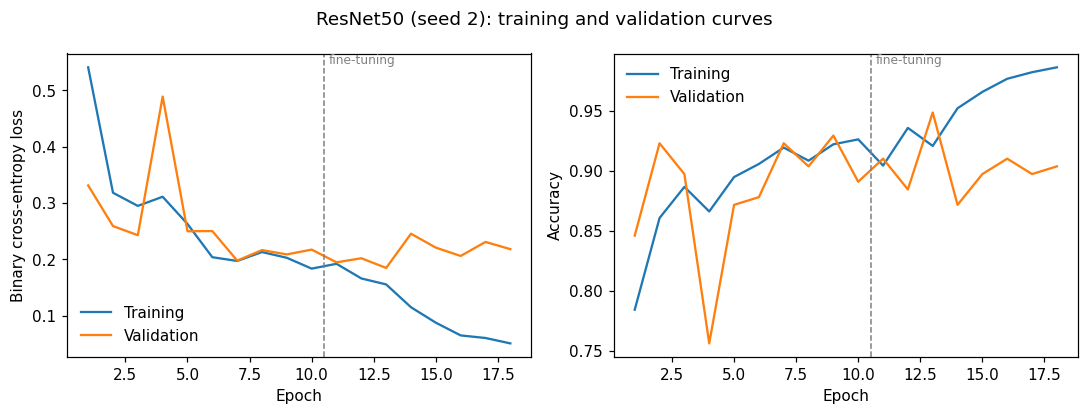

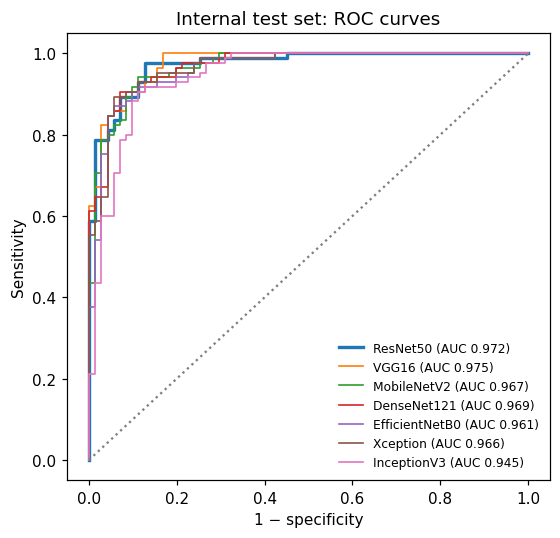

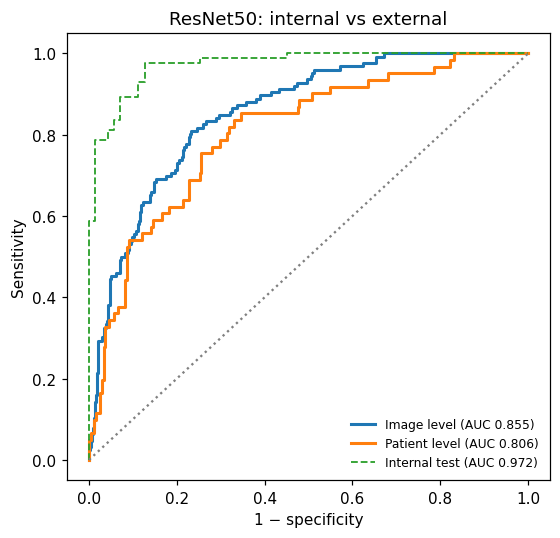

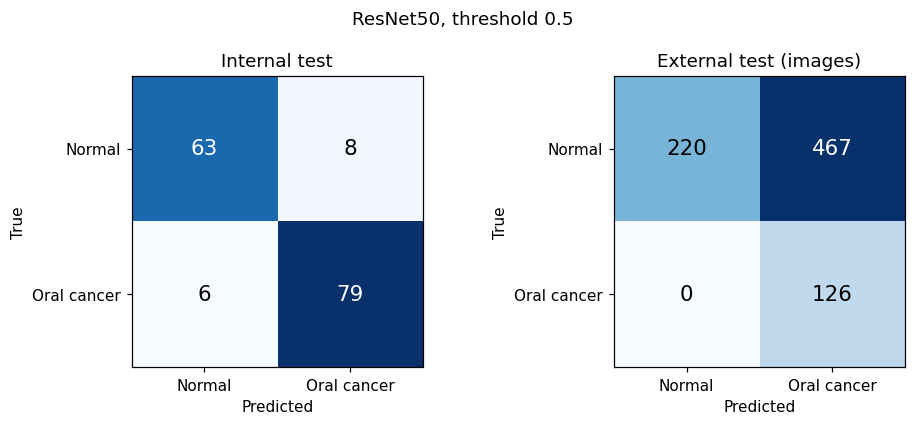

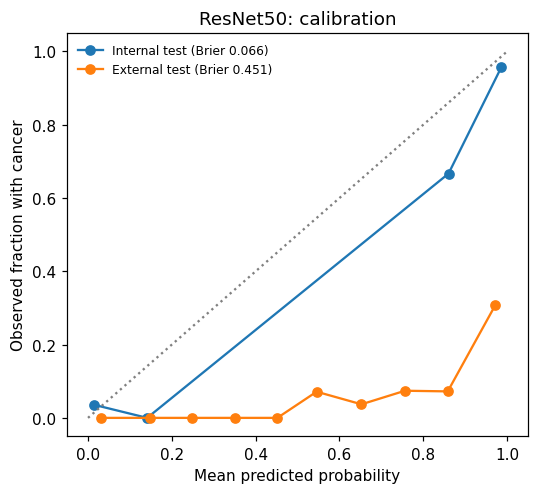

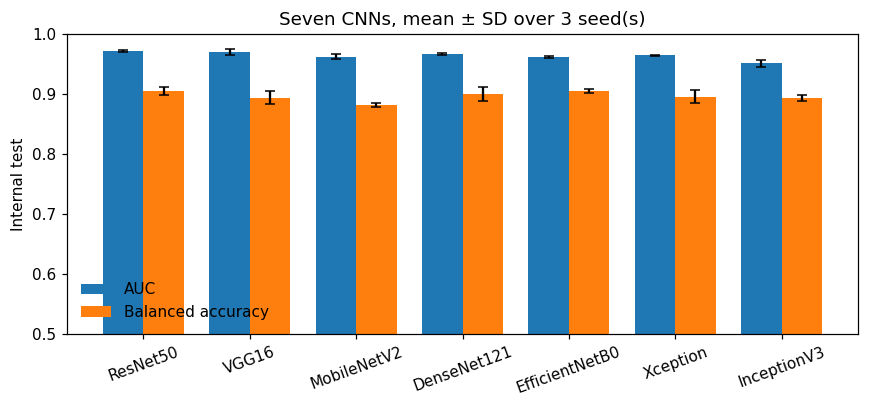

In [ ]:
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(FIGS / f"{name}.png", bbox_inches="tight"); fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)

# F1 training curves of the primary locked run
_, hist, _ = load_run(PRIMARY_MODEL, locked_seed[PRIMARY_MODEL])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, key, lab in ((ax[0], "loss", "Binary cross-entropy loss"), (ax[1], "accuracy", "Accuracy")):
    a.plot(hist.epoch, hist[key], label="Training"); a.plot(hist.epoch, hist["val_" + key], label="Validation")
    e1 = hist[hist.stage == 1].epoch.max(); a.axvline(e1 + 0.5, ls="--", c="grey", lw=1)
    a.text(e1 + 0.7, a.get_ylim()[1], "fine-tuning", va="top", fontsize=8, color="grey")
    a.set_xlabel("Epoch"); a.set_ylabel(lab); a.legend(frameon=False)
fig.suptitle(f"{PRIMARY_MODEL} (seed {locked_seed[PRIMARY_MODEL]}): training and validation curves")
savefig(fig, "fig_training_curves_primary")

# F2 ROC curves, internal test, all models
fig, ax = plt.subplots(figsize=(5.2, 5))
for name in MODELS:
    fpr, tpr, _ = roc_curve(y_test, P_TEST[name])
    ax.plot(fpr, tpr, lw=2.2 if name == PRIMARY_MODEL else 1.1, label=f"{name} (AUC {roc_auc_score(y_test, P_TEST[name]):.3f})")
ax.plot([0, 1], [0, 1], ls=":", c="grey"); ax.set_xlabel("1 − specificity"); ax.set_ylabel("Sensitivity")
ax.set_title("Internal test set: ROC curves"); ax.legend(fontsize=8, frameon=False, loc="lower right")
savefig(fig, "fig_roc_internal_all_models")

# F3 ROC external, primary: image vs patient level
fig, ax = plt.subplots(figsize=(5.2, 5))
for lab, yy, pp in (("Image level", y_ext, P_EXT[PRIMARY_MODEL]), ("Patient level", pat.y.values, pat[PRIMARY_MODEL].values)):
    fpr, tpr, _ = roc_curve(yy, pp); ax.plot(fpr, tpr, lw=2, label=f"{lab} (AUC {roc_auc_score(yy, pp):.3f})")
fpr, tpr, _ = roc_curve(y_test, P_TEST[PRIMARY_MODEL])
ax.plot(fpr, tpr, lw=1.2, ls="--", label=f"Internal test (AUC {roc_auc_score(y_test, P_TEST[PRIMARY_MODEL]):.3f})")
ax.plot([0, 1], [0, 1], ls=":", c="grey"); ax.set_xlabel("1 − specificity"); ax.set_ylabel("Sensitivity")
ax.set_title(f"{PRIMARY_MODEL}: internal vs external"); ax.legend(fontsize=8, frameon=False, loc="lower right")
savefig(fig, "fig_roc_external_primary")

# F4 confusion matrices, primary
fig, ax = plt.subplots(1, 2, figsize=(9, 3.9))
for a, (title, yy, pp) in zip(ax, (("Internal test", y_test, P_TEST[PRIMARY_MODEL]), ("External test (images)", y_ext, P_EXT[PRIMARY_MODEL]))):
    tn, fp, fn, tp = confusion(yy, pp); cm = np.array([[tn, fp], [fn, tp]])
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks([0, 1], ["Normal", "Oral cancer"]); a.set_yticks([0, 1], ["Normal", "Oral cancer"])
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(title)
fig.suptitle(f"{PRIMARY_MODEL}, threshold {THRESHOLD}")
savefig(fig, "fig_confusion_primary")

# F5 calibration
fig, ax = plt.subplots(figsize=(5, 4.6))
for lab, yy, pp in (("Internal test", y_test, P_TEST[PRIMARY_MODEL]), ("External test", y_ext, P_EXT[PRIMARY_MODEL])):
    bins = np.linspace(0, 1, 11); idx = np.clip(np.digitize(pp, bins) - 1, 0, 9)
    xs = [pp[idx == b].mean() for b in range(10) if (idx == b).sum() >= 5]
    ys = [yy[idx == b].mean() for b in range(10) if (idx == b).sum() >= 5]
    ax.plot(xs, ys, "o-", label=f"{lab} (Brier {brier_score_loss(yy, pp):.3f})")
ax.plot([0, 1], [0, 1], ls=":", c="grey"); ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed fraction with cancer")
ax.set_title(f"{PRIMARY_MODEL}: calibration"); ax.legend(frameon=False, fontsize=8)
savefig(fig, "fig_calibration_primary")

# F6 model comparison (internal test AUC and balanced accuracy, mean ± SD over seeds)
fig, ax = plt.subplots(figsize=(8, 3.8)); x = np.arange(len(MODELS)); w = 0.38
for k, (key, lab) in enumerate((("auc", "AUC"), ("balanced_accuracy", "Balanced accuracy"))):
    mu = [agg.loc[m, (key, "mean")] for m in MODELS]; sd = [agg.loc[m, (key, "std")] if len(SEEDS) > 1 else 0 for m in MODELS]
    ax.bar(x + (k - 0.5) * w, mu, w, yerr=sd, capsize=3, label=lab)
ax.set_xticks(x, MODELS, rotation=20); ax.set_ylim(0.5, 1.0); ax.set_ylabel("Internal test")
ax.set_title(f"Seven CNNs, mean ± SD over {len(SEEDS)} seed(s)"); ax.legend(frameon=False)
savefig(fig, "fig_model_comparison_internal")

## Step 12: Grad-CAM on real internal test images

Shows true positives, true negatives, and (if any) false positives and false negatives from the **internal (Kaggle) test set**, with the model's real probability.
The map is computed from the last convolutional block of the backbone, for the **predicted** class. It is a qualitative illustration only.
Only development (public repository) images are shown; external images are not displayed, in accordance with the licence of the external dataset.

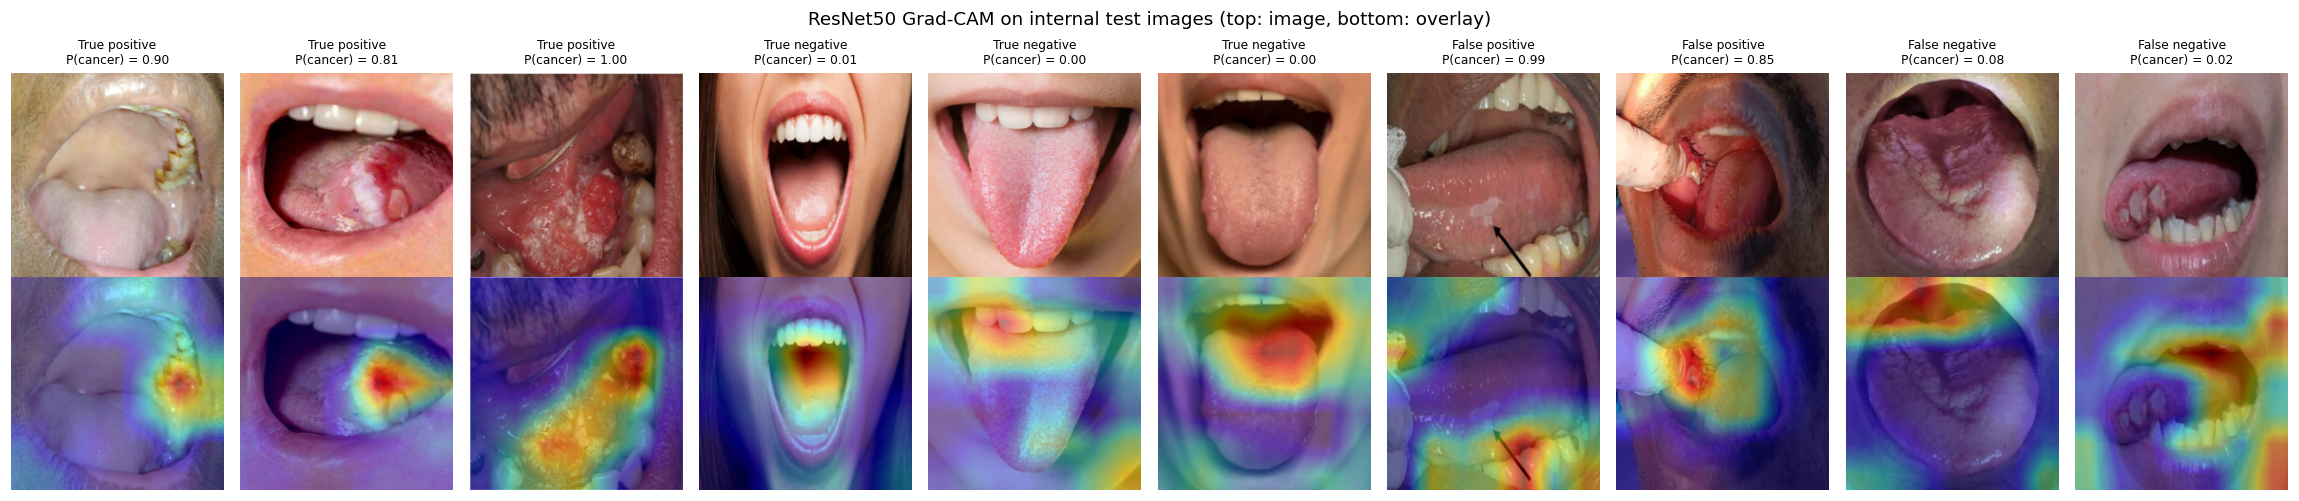

{'TP': 79, 'TN': 63, 'FP': 8, 'FN': 6}


In [ ]:
model, _, feat = build_model(PRIMARY_MODEL, locked_seed[PRIMARY_MODEL], weights=None)
model.load_weights(RUNS / f"{PRIMARY_MODEL}_seed{locked_seed[PRIMARY_MODEL]}" / "best.weights.h5")
grad_model = keras.Model(model.inputs, [feat, model.output])

def gradcam(img_uint8):
    x = tf.convert_to_tensor(img_uint8[None].astype("float32"))
    with tf.GradientTape() as tape:
        f, p = grad_model(x, training=False)
        prob = p[:, 0]
        score = prob if float(prob[0]) >= THRESHOLD else 1.0 - prob       # explain the predicted class
    g = tape.gradient(score, f)
    w = tf.reduce_mean(g, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(f * w[:, None, None, :], axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    cam = np.asarray(Image.fromarray(np.uint8(cam * 255)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)) / 255.0
    return cam, float(prob[0])

p_primary = P_TEST[PRIMARY_MODEL]; yh = (p_primary >= THRESHOLD).astype(int)
groups = {"TP": np.where((y_test == 1) & (yh == 1))[0], "TN": np.where((y_test == 0) & (yh == 0))[0],
          "FP": np.where((y_test == 0) & (yh == 1))[0], "FN": np.where((y_test == 1) & (yh == 0))[0]}
rng = np.random.default_rng(0)
pick = [(k, i) for k, n in (("TP", 3), ("TN", 3), ("FP", 2), ("FN", 2)) for i in rng.permutation(groups[k])[:n]]
names = {"TP": "True positive", "TN": "True negative", "FP": "False positive", "FN": "False negative"}

fig, ax = plt.subplots(2, len(pick), figsize=(2.1 * len(pick), 4.6))
for c, (k, i) in enumerate(pick):
    img = DATA["test"]["X"][i]; cam, prob = gradcam(img)
    ax[0, c].imshow(img); ax[1, c].imshow(img); ax[1, c].imshow(cam, cmap="jet", alpha=0.45)
    ax[0, c].set_title(f"{names[k]}\nP(cancer) = {prob:.2f}", fontsize=8)
    for r in (0, 1): ax[r, c].axis("off")
fig.suptitle(f"{PRIMARY_MODEL} Grad-CAM on internal test images (top: image, bottom: overlay)")
savefig(fig, "fig_gradcam_primary")
print({k: len(v) for k, v in groups.items()})
del model, grad_model; keras.backend.clear_session()

## Step 13: Software environment and summary of results

Prints the software environment, the lock file and all result tables.

In [ ]:
gpu = os.popen("nvidia-smi --query-gpu=name --format=csv,noheader").read().strip() or "none"
env = dict(python=platform.python_version(), tensorflow=tf.__version__, keras=keras.__version__,
           numpy=np.__version__, gpu=gpu, date=time.strftime("%Y-%m-%d"))
settings = dict(models=MODELS, primary=PRIMARY_MODEL, seeds=SEEDS, img_size=IMG_SIZE, batch_size=BATCH_SIZE,
                head_epochs=HEAD_EPOCHS, head_lr=HEAD_LR, ft_epochs=FT_EPOCHS, ft_lr=FT_LR, ft_fraction=FT_FRACTION,
                dense_units=DENSE_UNITS, dropout=DROPOUT, early_stopping_patience=ES_PATIENCE,
                lr_patience=LR_PATIENCE, lr_factor=LR_FACTOR, class_weights=USE_CLASS_WEIGHTS,
                threshold=THRESHOLD, augmentation=AUG, n_boot=N_BOOT)
json.dump(dict(environment=env, settings=settings, lock=lock), open(RESULTS / "run_record.json", "w"), indent=2)

train_info = pd.DataFrame([load_run(m, s)[2] for m in MODELS for s in SEEDS])
train_info.to_csv(TABLES / "training_runs_info.csv", index=False)

print("=== ENVIRONMENT ===", json.dumps(env, indent=1))
print("\n=== DATA ===\n", summary.to_string())
print("\n=== LOCK ===", json.dumps(lock, indent=1))
print("\n=== VALIDATION (mean over seeds) ===\n", val_summary.round(3).to_string())
print("\n=== INTERNAL TEST mean ± SD ===\n", tab_seeds.to_string())
print("\n=== INTERNAL TEST locked, 95% CI ===\n", tab_locked.to_string())
print("\n=== PAIRWISE TESTS ===\n", comp.to_string(index=False))
print("\n=== EXTERNAL image level ===\n", tab_ext.to_string())
print("\n=== EXTERNAL patient level ===\n", tab_pat.to_string())
p = train_info[train_info.model == PRIMARY_MODEL]
print(f"\n=== {PRIMARY_MODEL} training ===\n", p[["seed", "stage1_epochs", "stage2_epochs", "unfrozen_backbone_layers",
      "backbone_layers", "trainable_params_stage2", "total_params", "minutes"]].to_string(index=False))
print("\nAll tables:", TABLES, "\nAll figures:", FIGS)

=== ENVIRONMENT === {
 "python": "3.13.15",
 "tensorflow": "2.20.0",
 "keras": "3.13.2",
 "numpy": "2.1.3",
 "gpu": "Tesla T4",
 "date": "2026-09-23"
}

=== DATA ===
           images  cancer  normal
train        733     399     334
val          156      85      71
test         156      85      71
external     813     126     687

=== LOCK === {
 "time": "2026-09-23 10:21:55",
 "primary_model": "ResNet50",
 "locked_seed": {
  "VGG16": 1,
  "ResNet50": 2,
  "DenseNet121": 2,
  "EfficientNetB0": 0,
  "Xception": 1,
  "MobileNetV2": 0,
  "InceptionV3": 2
 },
 "best_model_on_validation": "VGG16",
 "threshold": 0.5
}

=== VALIDATION (mean over seeds) ===
                 val_auc_mean  val_auc_sd  val_bal_acc_mean
model                                                     
ResNet50               0.976       0.002             0.937
VGG16                  0.985       0.004             0.933
MobileNetV2            0.959       0.007             0.904
DenseNet121            0.968       0.002      

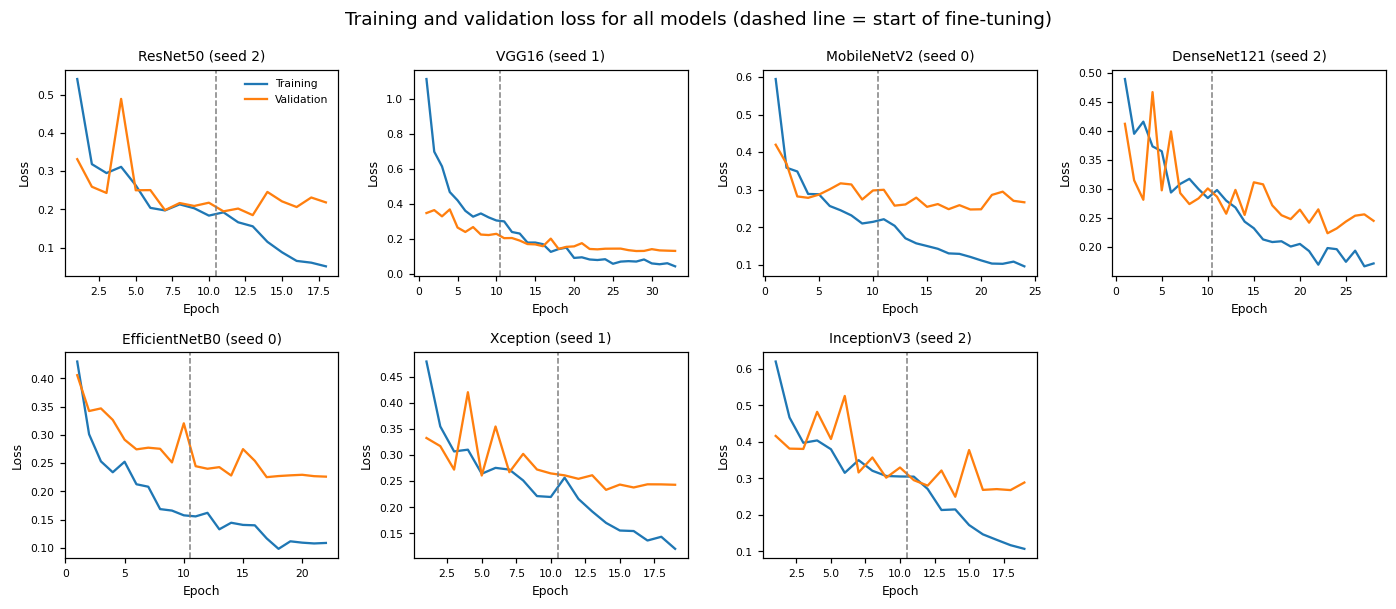

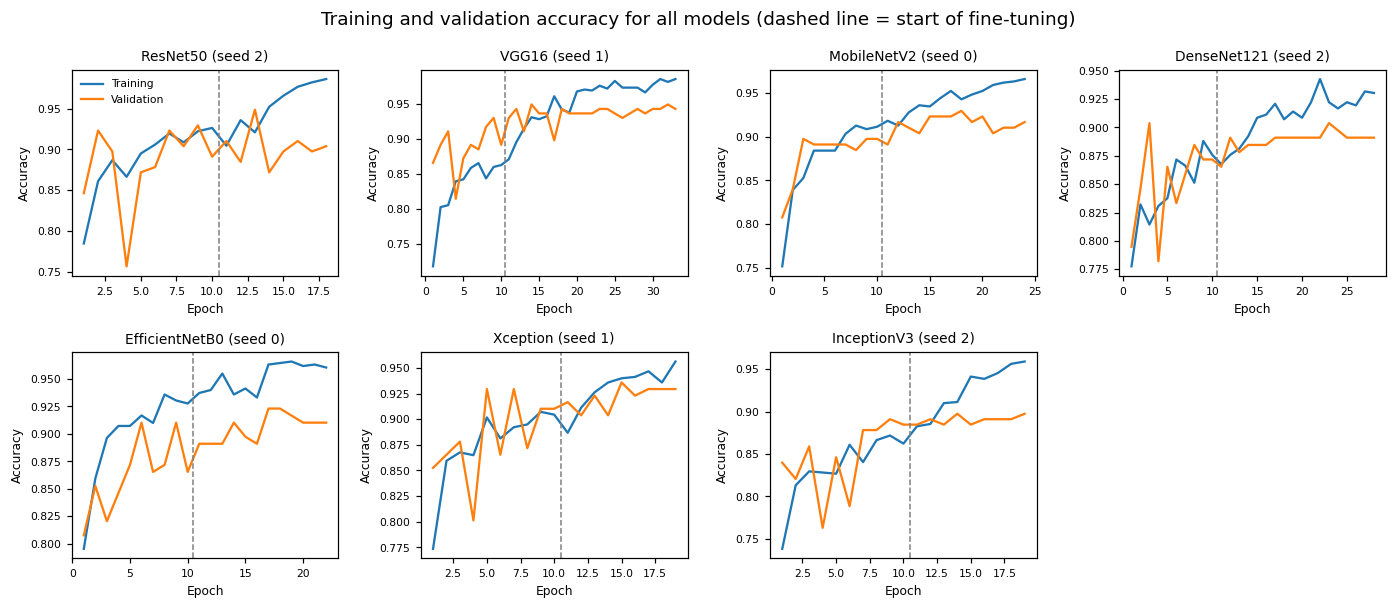

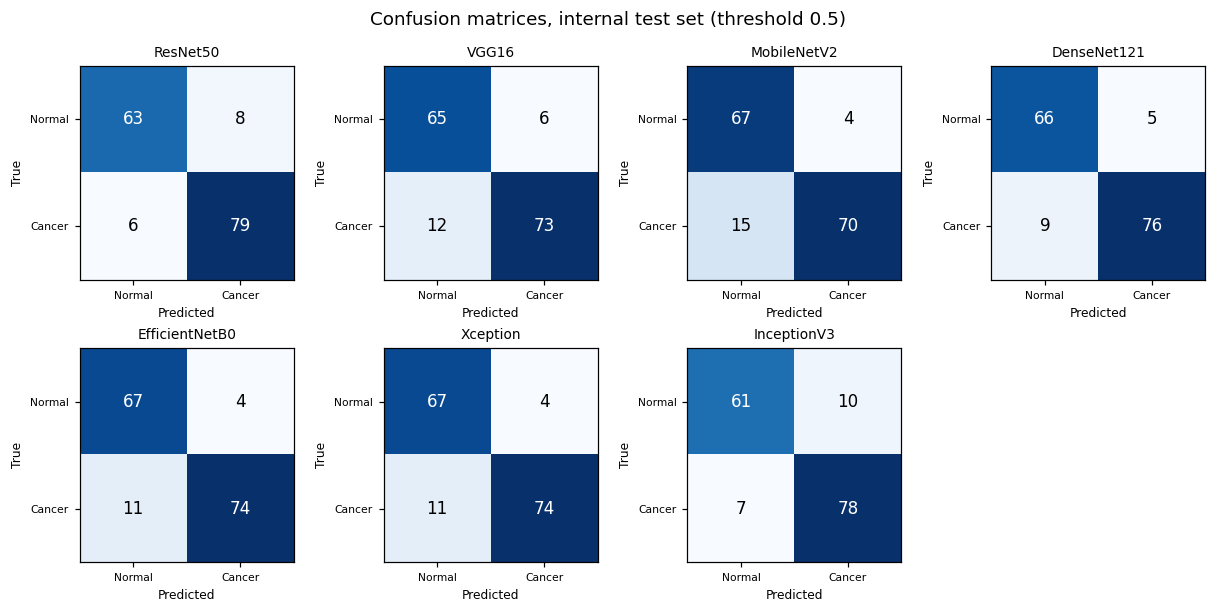

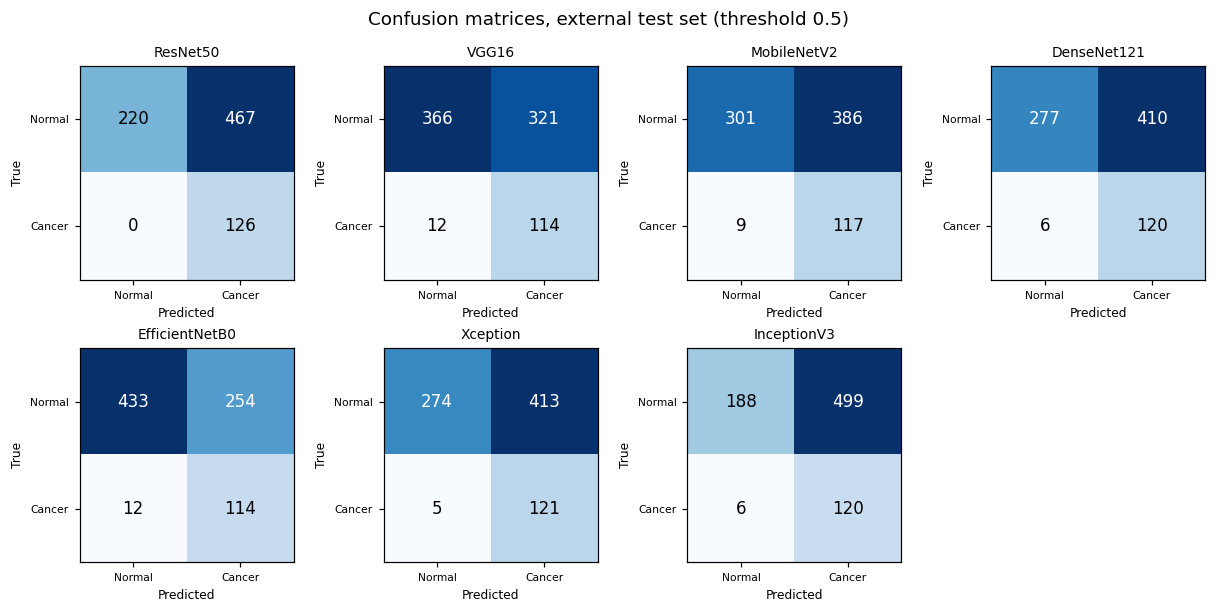

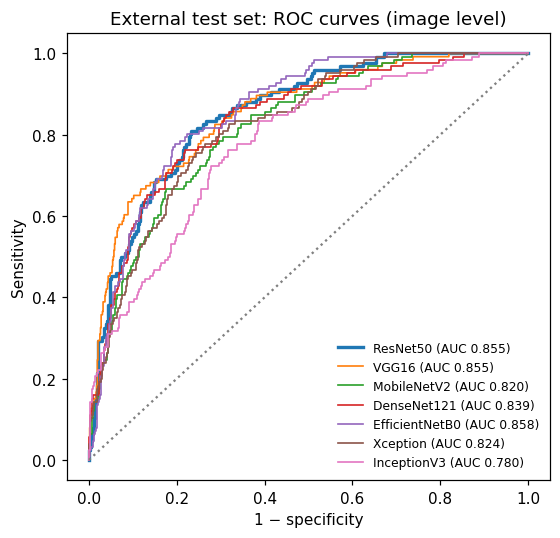

Supplementary figures saved in /content/drive/MyDrive/oral project/results_v2/figures


In [ ]:
# ===== Step 14: Supplementary figures for ALL 7 models =====
import math

def grid(n, w=3.2, h=2.8, cols=4):
    rows = math.ceil(n / cols)
    fig, ax = plt.subplots(rows, cols, figsize=(w * cols, h * rows))
    ax = np.atleast_1d(ax).ravel()
    for a in ax[n:]:
        a.axis("off")
    return fig, ax

# (a) training curves of every model (locked seed)
for key, lab in (("loss", "Loss"), ("accuracy", "Accuracy")):
    fig, ax = grid(len(MODELS))
    for a, name in zip(ax, MODELS):
        _, h, _ = load_run(name, locked_seed[name])
        a.plot(h.epoch, h[key], label="Training")
        a.plot(h.epoch, h["val_" + key], label="Validation")
        a.axvline(h[h.stage == 1].epoch.max() + 0.5, ls="--", c="grey", lw=1)
        a.set_title(f"{name} (seed {locked_seed[name]})", fontsize=9)
        a.set_xlabel("Epoch", fontsize=8); a.set_ylabel(lab, fontsize=8); a.tick_params(labelsize=7)
    ax[0].legend(fontsize=7, frameon=False)
    fig.suptitle(f"Training and validation {lab.lower()} for all models (dashed line = start of fine-tuning)")
    savefig(fig, f"supp_training_{key}_all_models")

# (b) confusion matrices of every model, internal and external
def cm_panel(a, y, p, title):
    tn, fp, fn, tp = confusion(y, p); cm = np.array([[tn, fp], [fn, tp]])
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=11,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks([0, 1], ["Normal", "Cancer"], fontsize=7); a.set_yticks([0, 1], ["Normal", "Cancer"], fontsize=7)
    a.set_xlabel("Predicted", fontsize=8); a.set_ylabel("True", fontsize=8); a.set_title(title, fontsize=9)

for setname, yy, P in (("internal", y_test, P_TEST), ("external", y_ext, P_EXT)):
    fig, ax = grid(len(MODELS), 2.8, 2.8)
    for a, name in zip(ax, MODELS):
        cm_panel(a, yy, P[name], name)
    fig.suptitle(f"Confusion matrices, {setname} test set (threshold {THRESHOLD})")
    savefig(fig, f"supp_confusion_{setname}_all_models")

# (c) external ROC curves of every model
fig, ax = plt.subplots(figsize=(5.2, 5))
for name in MODELS:
    fpr, tpr, _ = roc_curve(y_ext, P_EXT[name])
    ax.plot(fpr, tpr, lw=2.2 if name == PRIMARY_MODEL else 1.1,
            label=f"{name} (AUC {roc_auc_score(y_ext, P_EXT[name]):.3f})")
ax.plot([0, 1], [0, 1], ls=":", c="grey"); ax.set_xlabel("1 − specificity"); ax.set_ylabel("Sensitivity")
ax.set_title("External test set: ROC curves (image level)"); ax.legend(fontsize=8, frameon=False, loc="lower right")
savefig(fig, "supp_roc_external_all_models")
print("Supplementary figures saved in", FIGS)

## Step 15: Deep-feature near-duplicate audit

Added after the initial training round (see the note at the top). In the repeated analysis shown here, no validation, internal-test or external image reached the 0.95 threshold.

In [ ]:
# ===== Step 15: Second near-duplicate audit (deep-feature similarity) =====
# Catches cropped / zoomed / colour-shifted copies that pHash can miss.
# Uses a plain ImageNet ResNet50 (not the trained study models) as an independent feature extractor.
AUDIT_THRESHOLD = 0.95          # cosine similarity above this = flag for visual review
AUDIT_WEIGHTS = "imagenet"

fx = keras.applications.ResNet50(include_top=False, weights=AUDIT_WEIGHTS, pooling="avg",
                                 input_shape=(IMG_SIZE, IMG_SIZE, 3))
def embed(X):
    out = []
    for i in range(0, len(X), 64):
        x = keras.applications.resnet50.preprocess_input(X[i:i + 64].astype("float32"))
        out.append(fx.predict(x, verbose=0))
    E = np.concatenate(out)
    return E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-12)

EMB = {k: embed(DATA[k]["X"]) for k in ("train", "val", "test", "external")}
NAMES = {k: DATA[k]["df"]["clean_path" if k != "external" else "ext_path"].values for k in EMB}
EMB["development"] = np.vstack([EMB["train"], EMB["val"], EMB["test"]])
NAMES["development"] = np.concatenate([NAMES["train"], NAMES["val"], NAMES["test"]])
XS = {"development": np.vstack([DATA["train"]["X"], DATA["val"]["X"], DATA["test"]["X"]]),
      **{k: DATA[k]["X"] for k in ("train", "val", "test", "external")}}

checks = [("val", "train"), ("test", "train"), ("test", "val"), ("external", "development")]
audit_rows, flagged, top_pairs = [], [], {}
for q, ref in checks:
    S = EMB[q] @ EMB[ref].T
    j = S.argmax(1); s = S.max(1)
    audit_rows.append(dict(query_set=q, reference_set=ref, n_query=len(s),
                           median_max_similarity=round(float(np.median(s)), 3),
                           max_similarity=round(float(s.max()), 3),
                           n_flagged=int((s >= AUDIT_THRESHOLD).sum())))
    for i in np.where(s >= AUDIT_THRESHOLD)[0]:
        flagged.append(dict(query_set=q, query_image=NAMES[q][i], reference_set=ref,
                            nearest_image=NAMES[ref][j[i]], cosine=round(float(s[i]), 4)))
    order = np.argsort(-s)[:8]
    top_pairs[(q, ref)] = [(i, j[i], s[i]) for i in order]

audit = pd.DataFrame(audit_rows)
audit.to_csv(TABLES / "audit_deep_feature_similarity.csv", index=False)
pd.DataFrame(flagged, columns=["query_set", "query_image", "reference_set", "nearest_image", "cosine"]) \
  .to_csv(TABLES / "audit_flagged_pairs.csv", index=False)
print("Deep-feature near-duplicate audit (for each query image: its most similar reference image)")
display(audit)

# visual check of the 8 most similar pairs per comparison (internal review only; external images are not published)
fig, ax = plt.subplots(2 * len(checks), 4, figsize=(16, 4.4 * len(checks)))
for r, (q, ref) in enumerate(checks):
    for c, (i, jj, s) in enumerate(top_pairs[(q, ref)]):
        a = ax[2 * r + c // 4, c % 4]
        a.imshow(np.concatenate([XS[q][i], XS[ref][jj]], axis=1)); a.axis("off")
        a.set_title(f"{q} vs {ref}   cos = {s:.3f}", fontsize=9, color="red" if s >= AUDIT_THRESHOLD else "black")
fig.suptitle("Most similar image pairs per comparison (left: query, right: nearest reference). Red = flagged")
fig.tight_layout(); fig.savefig(RESULTS / "audit_top_pairs_REVIEW_ONLY.png", dpi=120); plt.show(); plt.close(fig)
del fx; keras.backend.clear_session()

Deep-feature near-duplicate audit (for each query image: its most similar reference image)


,query_set,reference_set,n_query,median_max_similarity,max_similarity,n_flagged
0,val,train,156,0.802,0.944,0
1,test,train,156,0.806,0.949,0
2,test,val,156,0.767,0.882,0
3,external,development,813,0.764,0.880,0


[Figure removed from the public version of this notebook: it shows images from the restricted-access external dataset.]


In [ ]:
# ===== Step 16: Evidence package (no images, no weights) =====
import hashlib, shutil, zipfile

PKG = RESULTS / "evidence_package"
if PKG.exists():
    shutil.rmtree(PKG)
for sub in ("data_audit", "runs", "tables", "figures"):
    (PKG / sub).mkdir(parents=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

# data documentation and split indices
for f in [CLEAN_DIR / "split.csv", EXT_DIR / "external.csv"] + sorted((CLEAN_DIR / "reports").glob("*.csv")) \
         + [CLEAN_DIR / "reports" / "settings.json"] + sorted((EXT_DIR / "reports").glob("*.csv")):
    if f.exists():
        shutil.copy2(f, PKG / "data_audit" / (f"external_{f.name}" if EXT_DIR in f.parents else f.name))

# every training run: history (log), predictions, run info
for rdir in sorted(RUNS.iterdir()):
    if (rdir / "done.json").exists():
        (PKG / "runs" / rdir.name).mkdir()
        for f in ("history.csv", "preds.csv", "done.json"):
            shutil.copy2(rdir / f, PKG / "runs" / rdir.name / f)

for f in sorted(TABLES.glob("*.csv")):
    shutil.copy2(f, PKG / "tables" / f.name)
for f in sorted(FIGS.glob("*.png")):
    shutil.copy2(f, PKG / "figures" / f.name)
for f in ("lock.json", "run_record.json", "external_predictions.csv"):
    if (RESULTS / f).exists():
        shutil.copy2(RESULTS / f, PKG / f)

# checksums of model checkpoints (weights themselves are uploaded separately)
ck = [dict(run=r.name, file="best.weights.h5", size_MB=round((r / "best.weights.h5").stat().st_size / 1e6, 1),
           sha256=sha256(r / "best.weights.h5"),
           locked=(r.name == f"{r.name.rsplit('_seed', 1)[0]}_seed{locked_seed.get(r.name.rsplit('_seed', 1)[0], -1)}"))
      for r in sorted(RUNS.iterdir()) if (r / "best.weights.h5").exists()]
pd.DataFrame(ck).to_csv(PKG / "checkpoint_checksums.csv", index=False)

(PKG / "README.txt").write_text(f"""Evidence package: oral cancer CNN study
Created: {time.strftime('%Y-%m-%d %H:%M')}

data_audit/   split.csv (exact train/val/test file lists), external.csv (external test list with patient IDs),
              per-source counts, duplicate pairs, cross-source overlap, folder-to-label mapping, file inventory
runs/         for every model x seed: history.csv (epoch-by-epoch training log), preds.csv (validation and
              internal-test probabilities per image), done.json (epochs, parameters, run time)
tables/       all result tables, including the deep-feature near-duplicate audit
figures/      all figures, generated directly from the files above
lock.json     model/seed selection made on validation data before test evaluation
run_record.json  software versions, GPU, and every hyperparameter
external_predictions.csv  external-test probabilities of the locked models
checkpoint_checksums.csv  SHA-256 of each model checkpoint (checkpoints deposited separately)

Images are not included: they are available from the original sources under their own licences.
""")

zip_path = RESULTS / "evidence_package.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in PKG.rglob("*"):
        if f.is_file():
            z.write(f, f.relative_to(PKG))

locked_dir = RESULTS / "locked_checkpoints"
locked_dir.mkdir(exist_ok=True)
for name in MODELS:
    src = RUNS / f"{name}_seed{locked_seed[name]}" / "best.weights.h5"
    shutil.copy2(src, locked_dir / f"{name}_seed{locked_seed[name]}.weights.h5")

print(f"Evidence package: {zip_path}  ({zip_path.stat().st_size / 1e6:.1f} MB)")
print(f"Locked checkpoints for Zenodo: {locked_dir}  ({sum(f.stat().st_size for f in locked_dir.iterdir()) / 1e6:.0f} MB)")

Evidence package: /content/drive/MyDrive/oral project/results_v2/evidence_package.zip  (8.6 MB)
Locked checkpoints for Zenodo: /content/drive/MyDrive/oral project/results_v2/locked_checkpoints  (858 MB)


### Internal test without flagged images (sensitivity analysis)

In the repeated analysis no internal-test image was flagged, so the table below is empty.

In [ ]:
fl = pd.read_csv(TABLES / "audit_flagged_pairs.csv"); display(fl)

fig, ax = plt.subplots(1, len(fl), figsize=(6 * len(fl), 3.4)); ax = np.atleast_1d(ax)
for a, (_, r) in zip(ax, fl.iterrows()):
    qi = list(NAMES[r.query_set]).index(r.query_image); ri = list(NAMES[r.reference_set]).index(r.nearest_image)
    a.imshow(np.concatenate([XS[r.query_set][qi], XS[r.reference_set][ri]], axis=1)); a.axis("off")
    a.set_title(f"{r.query_set} vs {r.reference_set}   cos = {r.cosine:.3f}", fontsize=10)
fig.savefig(RESULTS / "audit_flagged_pairs_REVIEW_ONLY.png", dpi=150); plt.show(); plt.close(fig)

# Sensitivity analysis: internal test WITHOUT the flagged test images
drop = set(fl.loc[fl.query_set == "test", "query_image"])
keep = ~test_df.clean_path.isin(drop).values
rows = {}
for name in MODELS:
    m = point_metrics(y_test[keep], P_TEST[name][keep])
    rows[name] = {k: round(m[k], 3) for k in ["accuracy", "balanced_accuracy", "sensitivity", "specificity", "auc"]}
sens = pd.DataFrame(rows).T
sens.to_csv(TABLES / "sensitivity_internal_test_without_flagged.csv")
print(f"Internal test without {len(drop)} flagged image(s): n = {keep.sum()}")
display(sens)

,query_set,query_image,reference_set,nearest_image,cosine


ValueError: Number of columns must be a positive integer, not 0

<Figure size 0x374 with 0 Axes>

### Review and removal of near-duplicates (used once, after the initial training round)

These cells were used once, after the initial training round, to inspect the pairs flagged by the deep-feature audit and to remove the four affected images. The removed images are listed in `oral_clean/reports/removed_after_deep_feature_audit.csv`, and the original partition is kept as `oral_clean/split_v1_before_deep_audit.csv`. They are not part of the repeated analysis and must not be re-run on the cleaned partition: the pair numbers in `SAME_PHOTO` refer to the ranking of the initial audit.

In [ ]:
REVIEW_FROM = 0.90
Y = {k: DATA[k]["y"] for k in ("train", "val", "test", "external")}
Y["development"] = np.concatenate([Y["train"], Y["val"], Y["test"]])
LAB = {0: "normal", 1: "cancer"}

cand = []
for q, ref in checks:
    S = EMB[q] @ EMB[ref].T
    for i in range(len(S)):
        j = int(S[i].argmax())
        if S[i, j] >= REVIEW_FROM:
            cand.append(dict(query_set=q, query_image=NAMES[q][i], query_label=LAB[Y[q][i]], qi=i,
                             reference_set=ref, ref_image=NAMES[ref][j], ref_label=LAB[Y[ref][j]], rj=j,
                             cosine=round(float(S[i, j]), 4)))
cand = pd.DataFrame(cand).sort_values("cosine", ascending=False).reset_index(drop=True)
cand.to_csv(TABLES / "audit_pairs_above_0.90.csv", index_label="pair")
print(f"{len(cand)} pairs with similarity >= {REVIEW_FROM}")

show = cand.head(40)
cols = 4; rows = max(1, int(np.ceil(len(show) / cols)))
fig, ax = plt.subplots(rows, cols, figsize=(16, 3.3 * rows)); ax = np.atleast_1d(ax).ravel()
for a in ax: a.axis("off")
for a, (k, r) in zip(ax, show.iterrows()):
    a.imshow(np.concatenate([XS[r.query_set][r.qi], XS[r.reference_set][r.rj]], axis=1))
    a.set_title(f"PAIR {k}: {r.query_set} ({r.query_label}) vs {r.reference_set} ({r.ref_label})\ncos = {r.cosine:.3f}",
                fontsize=8, color="red" if r.query_label != r.ref_label else "black")
fig.tight_layout(); plt.show(); plt.close(fig)

In [ ]:
SAME_PHOTO = [0, 1, 2]     # pairs of the initial audit confirmed visually as the same photograph

split_path = CLEAN_DIR / "split.csv"
backup = CLEAN_DIR / "split_v1_before_deep_audit.csv"
if not backup.exists():
    shutil.copy2(split_path, backup)          # keep the original for transparency
sp = pd.read_csv(backup)

removed = []
for k in SAME_PHOTO:
    r = cand.loc[k]
    if r.query_set == "external":
        print(f"Pair {k} involves an external image - not removed"); continue
    if r.query_label == r.ref_label:          # same label: drop the val/test copy, keep the training copy
        removed.append(dict(pair=k, image=r.query_image, reason=f"duplicate of {r.ref_image}"))
    else:                                     # conflicting labels: drop both images
        removed.append(dict(pair=k, image=r.query_image, reason=f"label conflict with {r.ref_image}"))
        removed.append(dict(pair=k, image=r.ref_image, reason=f"label conflict with {r.query_image}"))

removed = pd.DataFrame(removed).drop_duplicates("image")
removed.to_csv(CLEAN_DIR / "reports" / "removed_after_deep_feature_audit.csv", index=False)
new = sp[~sp.clean_path.isin(removed.image)]
new.to_csv(split_path, index=False)

display(removed)
print(f"Removed {len(removed)} images: {len(sp)} -> {len(new)}")
display(pd.crosstab(new.split, new.label, margins=True))

In [ ]:
# ===== Step 17: Secondary analysis - local threshold recalibration (patient-disjoint) =====
CAL_FRACTION, TARGET_SENS, CAL_SEED = 0.30, 0.90, 2026    # fixed before the recalibration was run

pat = pd.DataFrame({"pid": g_ext, "y": y_ext}).groupby("pid").y.max()
rng = np.random.default_rng(CAL_SEED)
cal_patients = []
for cls in (0, 1):                                         # stratified by patient cancer status
    ids = np.array(pat[pat == cls].index, dtype=object); rng.shuffle(ids)
    cal_patients += list(ids[:int(round(CAL_FRACTION * len(ids)))])
cal = np.isin(g_ext, cal_patients); tst = ~cal
print(f"Calibration part: {cal.sum()} images, {len(cal_patients)} patients | "
      f"Held-out test part: {tst.sum()} images, {len(pat) - len(cal_patients)} patients")

def thr_for_sens(y, p, target):
    pos = np.sort(p[y == 1])[::-1]                         # cancer scores, highest first
    return pos[int(np.ceil(target * len(pos))) - 1]        # lowest threshold keeping >= target sensitivity

def metr(y, p, t):
    yh = p >= t
    tp = ((y == 1) & yh).sum(); fn = ((y == 1) & ~yh).sum(); tn = ((y == 0) & ~yh).sum(); fp = ((y == 0) & yh).sum()
    se = tp / (tp + fn); sp = tn / (tn + fp)
    return dict(sensitivity=se, specificity=sp, balanced_accuracy=(se + sp) / 2,
                ppv=tp / (tp + fp) if tp + fp else np.nan, npv=tn / (tn + fn) if tn + fn else np.nan)

def cluster_ci(y, p, t, g, n=N_BOOT, seed=42):
    rng = np.random.default_rng(seed)
    groups = pd.Series(np.arange(len(y))).groupby(g).apply(np.array).values
    vals = []
    for _ in range(n):
        idx = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])
        if len(np.unique(y[idx])) == 2:
            vals.append(metr(y[idx], p[idx], t))
    v = pd.DataFrame(vals)
    return {k: (np.nanpercentile(v[k], 2.5), np.nanpercentile(v[k], 97.5)) for k in v}

rows = []
for name in MODELS:
    p = P_EXT[name]
    t_cal = thr_for_sens(y_ext[cal], p[cal], TARGET_SENS)
    for label, thr in (("fixed 0.5", 0.5), ("recalibrated", t_cal)):
        m = metr(y_ext[tst], p[tst], thr); ci = cluster_ci(y_ext[tst], p[tst], thr, g_ext[tst])
        rows.append({"model": name, "threshold": f"{label} ({thr:.3f})",
                     **{k: f"{m[k]:.3f} ({ci[k][0]:.3f}-{ci[k][1]:.3f})" for k in m}})
recal = pd.DataFrame(rows)
recal.to_csv(TABLES / "secondary_external_recalibration.csv", index=False)
print(f"Held-out external patients only. Threshold chosen on the calibration patients for sensitivity >= {TARGET_SENS}.")
display(recal)

Calibration part: 257 images, 91 patients | Held-out test part: 556 images, 212 patients
Held-out external patients only. Threshold chosen on the calibration patients for sensitivity >= 0.9.


,model,threshold,sensitivity,specificity,balanced_accuracy,ppv,npv
0,ResNet50,fixed 0.5 (0.500),1.000 (1.000-1.000),0.322 (0.266-0.382),0.661 (0.633-0.691),0.201 (0.134-0.281),1.000 (1.000-1.000)
1,ResNet50,recalibrated (0.946),0.790 (0.698-0.867),0.756 (0.703-0.804),0.773 (0.721-0.818),0.356 (0.237-0.487),0.955 (0.928-0.976)
2,VGG16,fixed 0.5 (0.500),0.901 (0.818-0.959),0.549 (0.483-0.617),0.725 (0.671-0.768),0.254 (0.166-0.357),0.970 (0.946-0.989)
3,VGG16,recalibrated (0.689),0.889 (0.797-0.954),0.640 (0.576-0.704),0.764 (0.710-0.807),0.296 (0.193-0.411),0.971 (0.951-0.988)
4,MobileNetV2,fixed 0.5 (0.500),0.951 (0.875-1.000),0.455 (0.394-0.511),0.703 (0.655-0.741),0.229 (0.150-0.322),0.982 (0.956-1.000)
5,MobileNetV2,recalibrated (0.479),0.963 (0.890-1.000),0.448 (0.387-0.504),0.706 (0.660-0.742),0.229 (0.151-0.321),0.986 (0.962-1.000)
6,DenseNet121,fixed 0.5 (0.500),0.951 (0.887-0.990),0.404 (0.339-0.467),0.677 (0.633-0.715),0.214 (0.140-0.300),0.980 (0.956-0.996)
7,DenseNet121,recalibrated (0.766),0.864 (0.776-0.935),0.617 (0.552-0.681),0.741 (0.690-0.787),0.278 (0.185-0.386),0.964 (0.936-0.985)
8,EfficientNetB0,fixed 0.5 (0.500),0.938 (0.885-0.981),0.638 (0.573-0.699),0.788 (0.748-0.826),0.306 (0.212-0.414),0.984 (0.967-0.997)
9,EfficientNetB0,recalibrated (0.380),0.951 (0.900-0.989),0.581 (0.511-0.648),0.766 (0.724-0.805),0.279 (0.192-0.380),0.986 (0.970-0.997)
